### KMeans

In [ ]:
 !wget "https://drive.google.com/uc?export=download&id=1lEccW5Y5_2z00VRtLGOAJOAU6YA9fl6W" -O E-commerce.csv

--2026-11-03 17:27:51--  https://drive.google.com/uc?export=download&id=1lEccW5Y5_2z00VRtLGOAJOAU6YA9fl6W
Resolving drive.google.com (drive.google.com)... 2404:6800:4009:81e::200e, 142.250.182.78
Connecting to drive.google.com (drive.google.com)|2404:6800:4009:81e::200e|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://drive.usercontent.google.com/download?id=1lEccW5Y5_2z00VRtLGOAJOAU6YA9fl6W&export=download [following]
--2026-11-03 17:27:52--  https://drive.usercontent.google.com/download?id=1lEccW5Y5_2z00VRtLGOAJOAU6YA9fl6W&export=download
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 2404:6800:4013:807::84, 142.250.143.132
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|2404:6800:4013:807::84|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 139827 (137K) [application/octet-stream]
Saving to: ‘E-commerce.csv’

E-commerce.csv      100%[===================>] 136.55K  -

<details>
<summary><b>Important Note</b></summary>

By default, `wget` names the downloaded file using the **last part of the URL path**.

For clean, direct URLs (like `[https://example.com/data/dataset.csv](https://example.com/data/dataset.csv)`), the last segment is `dataset.csv`. In that case, `wget` naturally saves it as `dataset.csv` without needing `-O`.

However, with Google Drive download links:

1. **How `wget` reads the URL:**
In `[https://drive.google.com/uc?export=download&id=](https://drive.google.com/uc?export=download&id=)...`, the URL path ends at `/uc`. The file identifier and export settings are URL query parameters (`?export=...&id=...`).
If you omit `-O`, `wget` parses `/uc` and saves the file locally as:
```text
uc?export=download&id=1lEccW5Y5_2z00VRtLGOAJOAU6YA9fl6W

```


or simply `uc`.  

2. **Why Google Drive doesn't supply the filename directly in the URL:**
Google Drive provides the original file name (`E-commerce.csv`) inside an HTTP response header called `Content-Disposition`, rather than in the URL path itself. By default, `wget` ignores this header and strictly relies on the URL text.  

3. **What `-O` does:**
The `-O` (uppercase "O" for *Output Document*) flag forces `wget` to write the incoming stream directly into the filename you specify (`E-commerce.csv`), bypassing its default URL parsing.


#### Alternative: `--content-disposition`

If you don't want to type out the output filename manually, you can instruct `wget` to read the server's header:

```bash
!wget --content-disposition "https://drive.google.com/uc?export=download&id=1lEccW5Y5_2z00VRtLGOAJOAU6YA9fl6W"

```

This tells `wget` to inspect the `Content-Disposition` header sent by Google Drive and automatically save the file with its intended name.
</details>

In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('E-commerce.csv')

In [4]:
df.head()

,ID,n_clicks,n_visits,amount_spent,amount_discount,days_since_registration,profile_information
0,1476,130,65,213.905831,31.600751,233,235
1,1535,543,46,639.223004,5.689175,228,170
2,1807,520,102,1157.402763,844.321606,247,409
3,1727,702,83,1195.903634,850.041757,148,200
4,1324,221,84,180.754616,64.283300,243,259


In [8]:
X = df.drop(['ID'], axis=1)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       2500 non-null   int64  
 1   n_clicks                 2500 non-null   int64  
 2   n_visits                 2500 non-null   int64  
 3   amount_spent             2500 non-null   float64
 4   amount_discount          2500 non-null   float64
 5   days_since_registration  2500 non-null   int64  
 6   profile_information      2500 non-null   int64  
dtypes: float64(2), int64(5)
memory usage: 136.8 KB


In [10]:
X.describe()

,n_clicks,n_visits,amount_spent,amount_discount,days_since_registration,profile_information
count,2500.00000,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000
mean,408.68000,94.475600,1445.090745,388.508637,200.973600,201.040400
std,186.41409,38.866356,1167.663473,487.143968,99.136618,100.139213
min,50.00000,10.000000,0.000000,0.000000,0.000000,0.000000
25%,274.75000,67.000000,609.618538,56.298615,130.000000,132.000000
50%,378.00000,92.000000,1036.189112,137.454623,200.000000,201.000000
75%,522.00000,119.000000,1949.270949,679.540536,268.000000,270.000000
max,1246.00000,259.000000,6567.402267,2428.406527,514.000000,585.000000


<details>
<summary><b>Important Note</b></summary>

`df.head()` inspects the **structure and raw values** of your data, while `df.describe()` calculates **summary statistics** across columns.

| Feature | `df.head(n)` | `df.describe()` |
| --- | --- | --- |
| **Primary Purpose** | Visual preview of individual rows | Statistical distribution overview |
| **Default Output** | First 5 rows of all columns | Summary metrics for numerical columns |
| **Output Type** | Actual row values (strings, dates, floats, etc.) | Aggregated statistics (`mean`, `std`, `min`, `max`, percentiles) |
| **Best Used For** | Checking column names, formatting, and row structure | Detecting outliers, scale/spread, and missing values |

---

### Key Differences in Detail

* **`df.head(n=5)`**
* Displays the first $n$ rows exactly as they appear in the dataset.
* Shows all data types (numerical, text, datetime, boolean).
* Helps verify that data loaded correctly, column headers match expectations, and values aren't shifted.


* **`df.describe()`**
* By default, computes 8 metrics for numeric columns:
* `count`: Non-null value count
* `mean` and `std`: Average and standard deviation
* `min` and `max`: Minimum and maximum values
* `25%`, `50%` (median), `75%`: Quartiles


* Excludes categorical/string columns by default. To summarize non-numeric data (showing `unique`, `top`, and `freq`), pass the include parameter:
```python
df.describe(include="all")   # includes numerical and non-numerical columns
df.describe(include=["object"])  # only categorical/text columns

```
</details>

### Capping Outliers as HW

In [11]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(X)
X=scaler.transform(X)



In [12]:
from sklearn.cluster import KMeans

k = 4 ## choose randomly

kmeans=KMeans(n_clusters=k,random_state=42)
y=kmeans.fit_predict(X)



In [14]:
y

array([2, 3, 2, ..., 2, 1, 0], shape=(2500,), dtype=int32)

In [15]:
kmeans.inertia_ ## inertia means WCSS

8338.456566387742

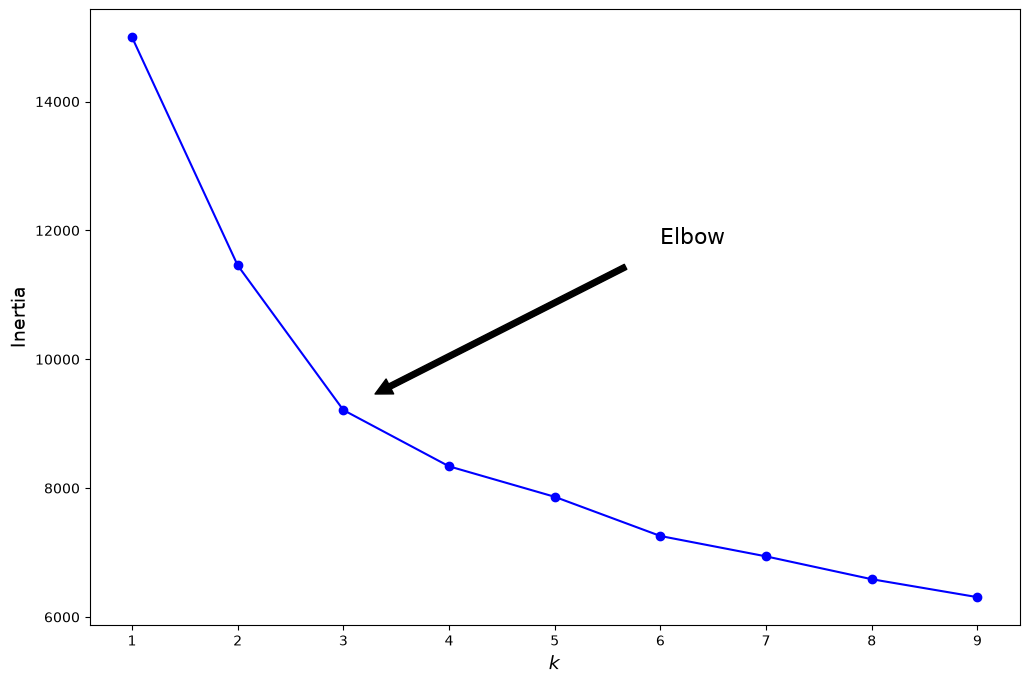

In [16]:
kmeans_per_k = [KMeans(n_clusters=k, random_state=42).fit(X)
                for k in range(1, 10)]

inertias = [model.inertia_ for model in kmeans_per_k]


plt.figure(figsize=(12, 8))
plt.plot(range(1, 10), inertias, "bo-")
plt.xlabel("$k$", fontsize=14)
plt.ylabel("Inertia", fontsize=14)
plt.annotate('Elbow',
             xy=(3, inertias[2]),
             xytext=(0.55, 0.55),
             textcoords='figure fraction',
             fontsize=16,
             arrowprops=dict(facecolor='black', shrink=0.1)
            )
plt.show()

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


# Scenario 1: Good Clustering
# Create two well-separated clusters using make_blobs
X_good, _ = make_blobs(n_samples=300,
                       centers=[[0, 0], [5, 5]],
                       cluster_std=0.5,
                       random_state=42)

# Apply k-means clustering (k=2)
kmeans_good = KMeans(n_clusters=2, random_state=42)
labels_good = kmeans_good.fit_predict(X_good)

Good clustering silhouette score: 0.878


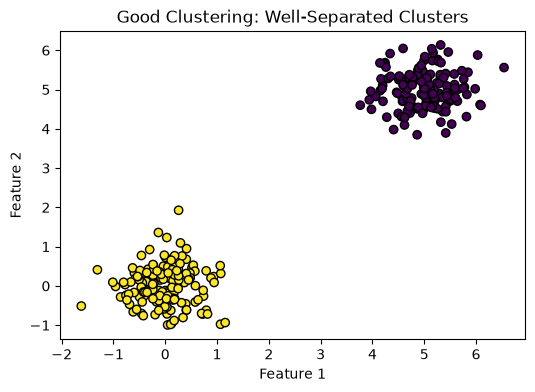

In [3]:
# Compute silhouette score
sil_score_good = silhouette_score(X_good, labels_good)
print(f"Good clustering silhouette score: {sil_score_good:.3f}")

# Plot the good clustering scenario
plt.figure(figsize=(6, 4))
plt.scatter(X_good[:, 0], X_good[:, 1], c=labels_good, cmap='viridis', edgecolor='k')
plt.title("Good Clustering: Well-Separated Clusters")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

Worst clustering silhouette score: 0.339


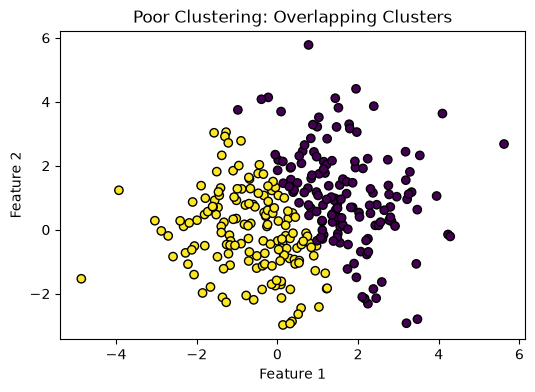

In [4]:
X_bad, _ = make_blobs(n_samples=300,
                      centers=[[0, 0], [1, 1]],  # Centers close to each other
                      cluster_std=1.5,           # Larger spread to create overlap
                      random_state=42)

# Apply k-means clustering (k=2)
kmeans_bad = KMeans(n_clusters=2, random_state=42)
labels_bad = kmeans_bad.fit_predict(X_bad)

# Compute silhouette score
sil_score_bad = silhouette_score(X_bad, labels_bad)
print(f"Worst clustering silhouette score: {sil_score_bad:.3f}")

# Plot the poor clustering scenario
plt.figure(figsize=(6, 4))
plt.scatter(X_bad[:, 0], X_bad[:, 1], c=labels_bad, cmap='viridis', edgecolor='k')
plt.title("Poor Clustering: Overlapping Clusters")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

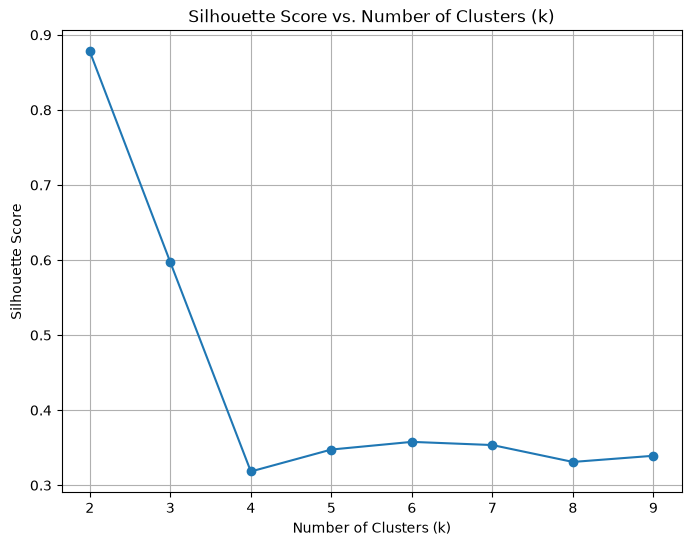

In [5]:
from sklearn.metrics import silhouette_score
k_values=range(2,10)
silhouette=[]
for k in k_values:
  kmeans=KMeans(n_clusters=k,random_state=42,n_init=10)
  labels=kmeans.fit_predict(X_good)
  score=silhouette_score(X_good,labels)
  silhouette.append(score)
plt.figure(figsize=(8, 6))
plt.plot(k_values, silhouette, marker='o')
plt.title("Silhouette Score vs. Number of Clusters (k)")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.xticks(k_values)
plt.grid(True)
plt.show()